<a href="https://colab.research.google.com/github/allnlk/ML/blob/main/%D0%9B%D0%A05_%D0%9A%D1%83%D0%B1%D1%80%D0%B0%D0%BA_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [4]:
# Імпортуйте необхідні бібліотеки
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.models import Sequential

warnings.filterwarnings('ignore')
plt.style.use('default')


In [5]:
# Завантажте датасет з Kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Path to dataset files: /kaggle/input/daily-climate-time-series-data-delhi-india


In [6]:
# Зчитайте датасет у DataFrame та перегляньте дані
df = pd.read_csv(os.path.join(path, 'kaggel_weather_2013_to_2024.csv'))
display(df)


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3552,3552,11/26/2024,25.8,13.6,18.6,25.8,13.6,18.6,65.9,0.0,...,24,48,1700.22,896.24,1225.74,1700.22,896.24,1225.74,12.2,242.171864
3553,3553,11/27/2024,26.2,12.5,18.4,26.2,12.5,18.4,61.0,0.0,...,24,48,1598.20,762.50,1122.40,1598.20,762.50,1122.40,13.7,236.769595
3554,3554,11/28/2024,25.8,11.5,17.9,25.8,11.5,17.9,63.1,0.0,...,24,48,1627.98,725.65,1129.49,1627.98,725.65,1129.49,14.3,243.117035
3555,3555,11/29/2024,25.0,10.6,18.0,25.0,10.6,18.0,60.0,0.0,...,24,48,1500.00,636.00,1080.00,1500.00,636.00,1080.00,14.4,237.638344


**ДАТА** : Дата спостереження.

**Температура** : tempmax, tempmin, temp.

**Відчутна температура**: feelslikemax, feelslikemin, feelslike.

**Вологість** : Середня відносна вологість.

**Опади** : precip, precipprob, precipcover.

**Вітер і тиск** : windspeed, sealevelpressure.

**Умови** : Опис погоди (Ясно, Дощ, Хмарно тощо).

**Похідні показники** : temp_range, heat_index.

Підготовка даних

In [7]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу

df['DATE'] = pd.to_datetime(df['DATE'])
df = df.sort_values('DATE')
df = df.drop(columns=['Unnamed: 0'])
df = df.set_index('DATE')
df.head()

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [8]:
# Перегляньте інформацію про структуру датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month                  3557 non-null  

In [9]:
# Перевірте наявність пропущених значень
df.isnull().sum()


,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0


Графік температури

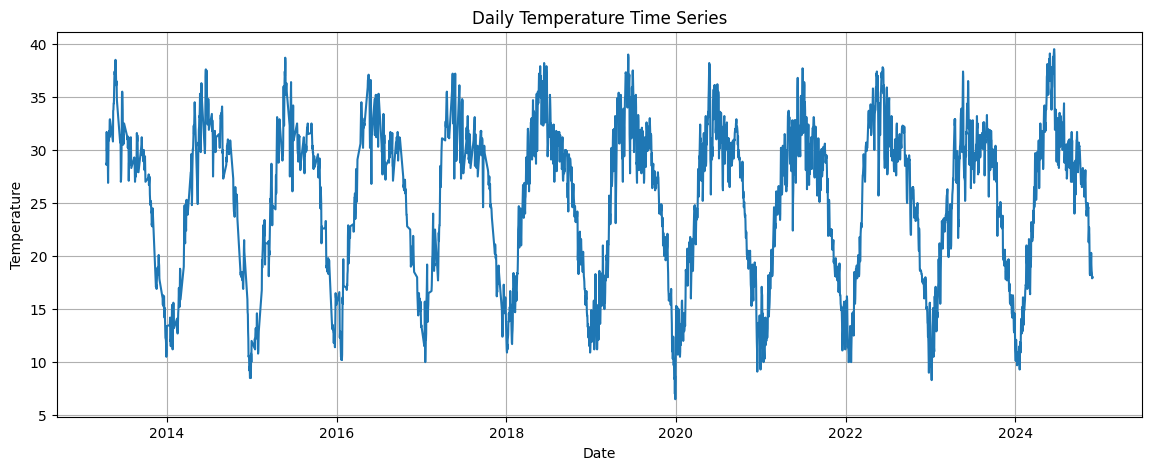

In [10]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14,5))
plt.plot(df['temp'])
plt.title('Daily Temperature Time Series')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.grid()
plt.show()

Ковзне середнє

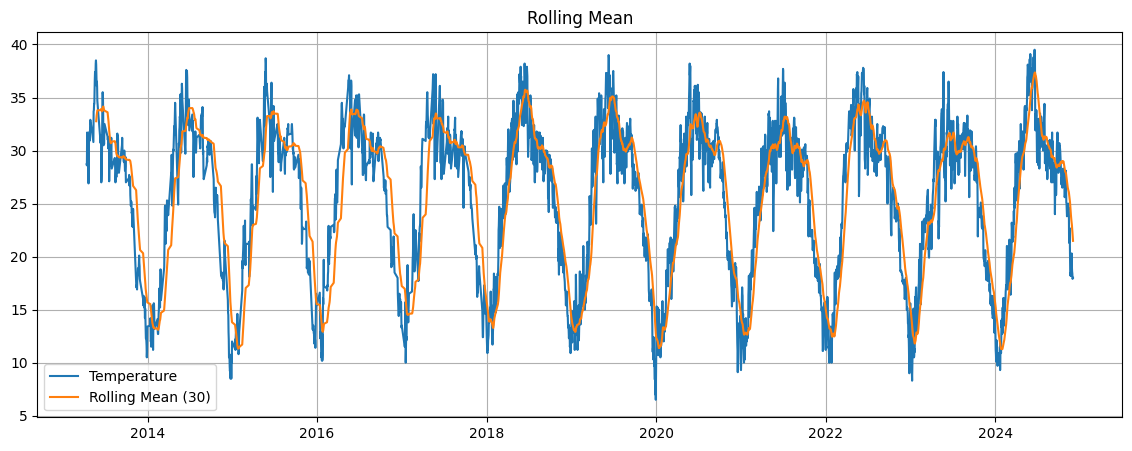

In [11]:
# Обчисліть та візуалізуйте ковзне середнє температури
df['rolling_mean'] = df['temp'].rolling(window=30).mean()

plt.figure(figsize=(14,5))
plt.plot(df['temp'], label='Temperature')
plt.plot(df['rolling_mean'], label='Rolling Mean (30)')
plt.title('Rolling Mean')
plt.legend()
plt.grid()
plt.show()

Розподіл температури

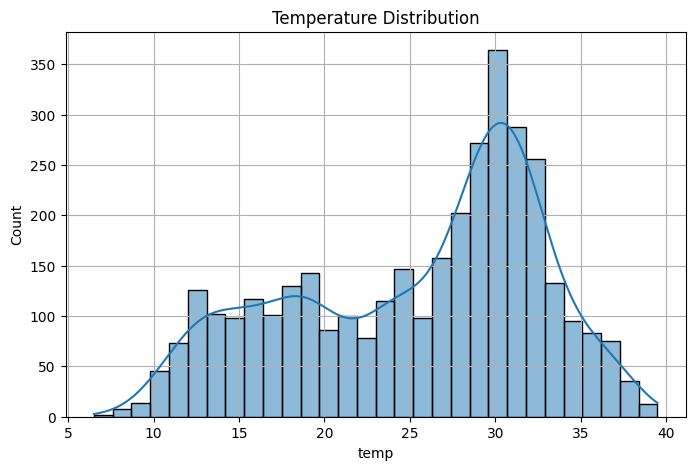

In [12]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(8,5))
sns.histplot(df['temp'], bins=30, kde=True)
plt.title('Temperature Distribution')
plt.grid()
plt.show()

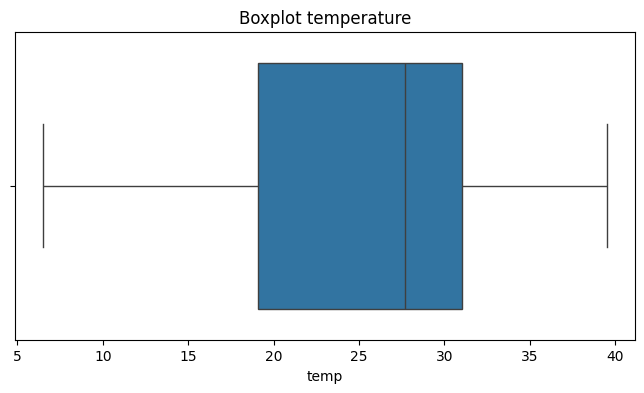

In [13]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(8,4))
sns.boxplot(x=df['temp'])
plt.title('Boxplot temperature')
plt.show()

Аналіз автокореляції
ACF

PACF

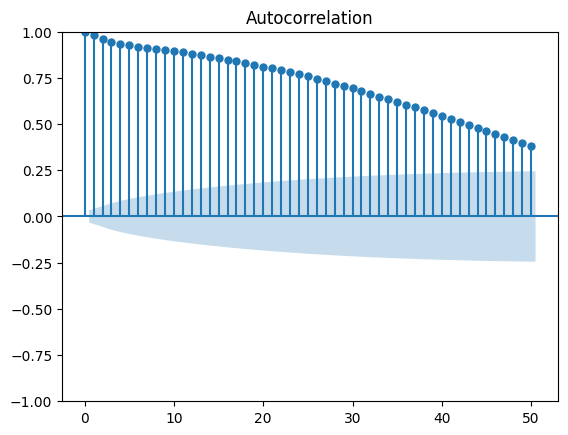

In [14]:
# Побудуйте графік автокореляційної функції (ACF)
plot_acf(df['temp'], lags=50)
plt.show()


Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

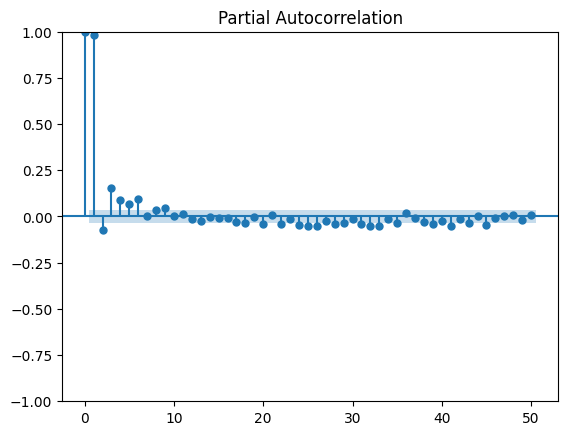

In [15]:
# Побудуйте графік часткової автокореляційної функції (PACF)
plot_pacf(df['temp'], lags=50)
plt.show()


Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [16]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
target = df['temp'].copy()

split_index = int(len(target) * 0.8)

train = target.iloc[:split_index]
test = target.iloc[split_index:]

print('Train size:', len(train))
print('Test size:', len(test))


Train size: 2845
Test size: 712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [17]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
train_arima = train.reset_index(drop=True)

arima_model = ARIMA(train_arima, order=(5, 1, 2))
arima_fit = arima_model.fit()

arima_forecast = arima_fit.forecast(steps=len(test))
arima_forecast.index = test.index

print(arima_forecast.head())

DATE
2022-12-20    14.895737
2022-12-21    15.071189
2022-12-22    15.161451
2022-12-23    15.179429
2022-12-24    15.200756
Name: predicted_mean, dtype: float64


In [18]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 2845
Model:                 ARIMA(5, 1, 2)   Log Likelihood               -4969.050
Date:                Fri, 09 Oct 2026   AIC                           9954.101
Time:                        10:06:21   BIC                          10001.724
Sample:                             0   HQIC                          9971.277
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1810      0.227      0.799      0.424      -0.263       0.625
ar.L2          0.1094      0.205      0.533      0.594      -0.293       0.511
ar.L3         -0.1108      0.049     -2.242      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

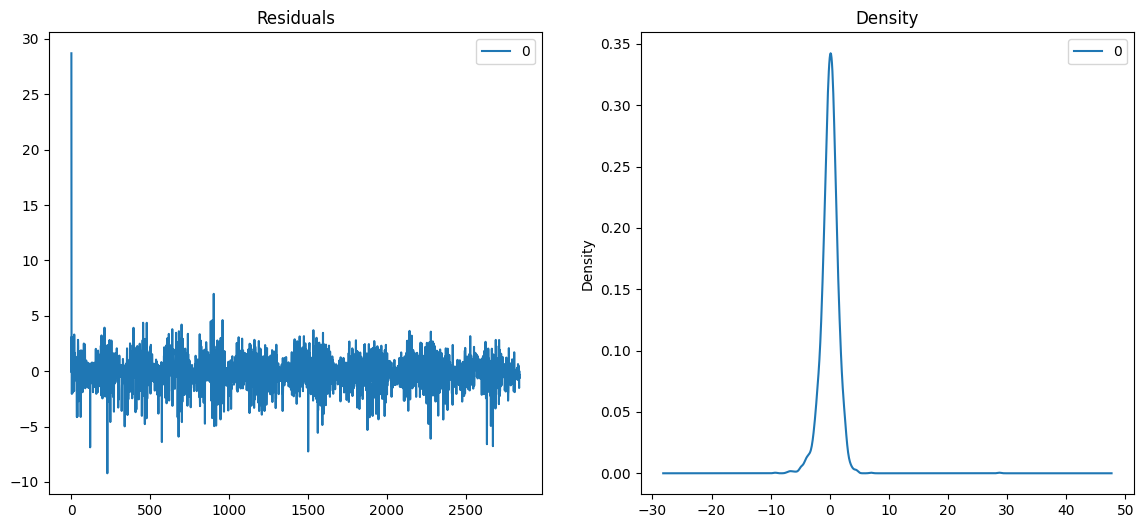

In [54]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = pd.DataFrame(arima_fit.resid)
fig,ax = plt.subplots(1, 2, figsize=(14, 6))
residuals.plot(title='Residuals', ax=ax[0])
residuals.plot(kind='kde', title='Density', ax=ax[1])
plt.show()

In [20]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def mape(y_true, y_pred):
  y_true = np.array(y_true)
  y_pred = np.array(y_pred)
  mask = y_true !=0
  return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

arima_mae = mean_absolute_error(test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test, arima_forecast))
arima_mape = mape(test, arima_forecast)

print('ARIMA MAE:', arima_mae)
print('ARIMA RMSE:', arima_rmse)
print('ARIMA MAPE:', arima_mape)


ARIMA MAE: 10.92780938078051
ARIMA RMSE: 12.500912027305812
ARIMA MAPE: 39.591987075351994


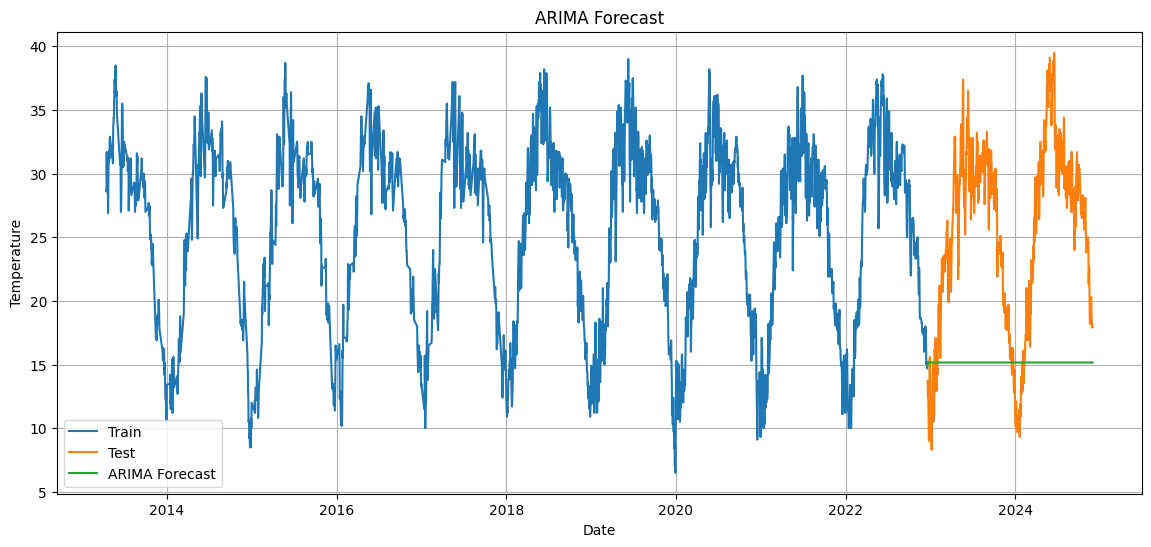

In [21]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14,6))
plt.plot(train.index, train, label='Train')
plt.plot(test.index, test, label='Test')
plt.plot(arima_forecast.index, arima_forecast, label='ARIMA Forecast')
plt.title('ARIMA Forecast')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.legend()
plt.grid(True)
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [22]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_df = df.reset_index()[['DATE', 'temp']].copy()
prophet_df.columns = ['ds', 'y']

prophet_train = prophet_df.iloc[:split_index].copy()
prophet_test =  prophet_df.iloc[split_index:].copy()


In [24]:
# Створіть та навчіть модель Prophet
from prophet import Prophet

prophet_model = Prophet(
    daily_seasonality=False,
    weekly_seasonality=True,
    yearly_seasonality=True
)

prophet_model.fit(prophet_train)

Прогноз

In [26]:
# Побудуйте прогноз Prophet для тестового періоду
future = prophet_model.make_future_dataframe(periods=len(prophet_test), freq='D')
prophet_forecast_full = prophet_model.predict(future)

prophet_forecast = prophet_forecast_full[['ds', 'yhat']].tail(len(prophet_test)).copy()
prophet_forecast = prophet_forecast.set_index('ds')

prophet_test_indexes = prophet_test.set_index('ds')


In [28]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_mae = mean_absolute_error(prophet_test_indexes['y'], prophet_forecast['yhat'])
prophet_rmse = np.sqrt(mean_squared_error(prophet_test_indexes['y'], prophet_forecast['yhat']))
prophet_mape = mape(prophet_test_indexes['y'], prophet_forecast['yhat'])

print('Prophet MAE:', prophet_mae)
print('Prophet RMSE:', prophet_rmse)
print('Prophet MAPE:', prophet_mape)



Prophet MAE: 2.004679994301011
Prophet RMSE: 2.5901965298397274
Prophet MAPE: 9.027934868552647


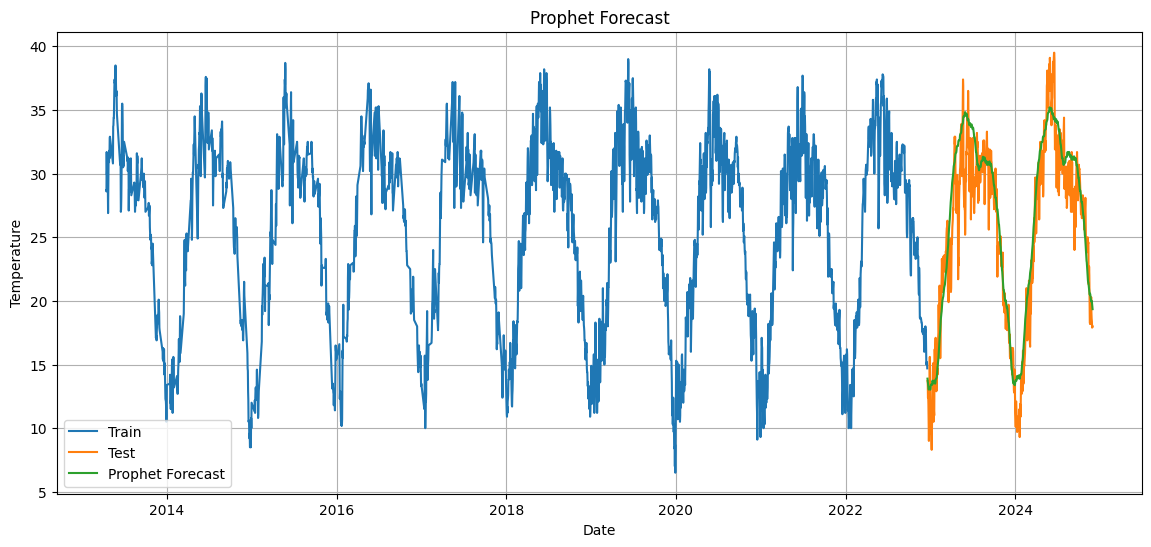

In [31]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14,6))
plt.plot(prophet_train['ds'], prophet_train['y'], label='Train')
plt.plot(prophet_test['ds'], prophet_test['y'], label='Test')
plt.plot(prophet_forecast.index, prophet_forecast['yhat'], label='Prophet Forecast')
plt.title('Prophet Forecast')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.legend()
plt.grid(True)
plt.show()


In [34]:
# Побудуйте компоненти моделі Prophet


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [33]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(df[['temp']])

sequence_length = 30

X = []
y = []

for i in range(sequence_length, len(scaled_values)):
  X.append(scaled_values[i-sequence_length:i, 0])
  y.append(scaled_values[i, 0])

X = np.array(X)
y = np.array(y)

X = X.reshape((X.shape[0], X.shape[1], 1))

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (3527, 30, 1)
y shape: (3527,)


In [36]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
split_lstm = int(len(X) * 0.8)

X_train = X[:split_lstm]
X_test = X[split_lstm:]

y_train = y[:split_lstm]
y_test = y[split_lstm:]

print('X shape:', X.shape)
print('y shape:', y.shape)


X shape: (3527, 30, 1)
y shape: (3527,)


In [37]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
split_lstm = int(len(X) * 0.8)

X_train = X[:split_lstm]
X_test = X[split_lstm:]

y_train = y[:split_lstm]
y_test = y[split_lstm:]

print('X_train', X_train.shape)
print('X_test', X_test.shape)

X_train (2821, 30, 1)
X_test (706, 30, 1)


In [40]:
# Навчіть LSTM-модель
lstm_model = Sequential()
lstm_model.add(LSTM(30, return_sequences=True, input_shape=[X_train.shape[1], 1]))
lstm_model.add(LSTM(30))
lstm_model.add(Dense(1))

lstm_model.compile(optimizer='adam', loss='mse')

In [42]:
# Виведіть структуру LSTM-моделі
history = lstm_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0327 - val_loss: 0.0061
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0068 - val_loss: 0.0052
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0057 - val_loss: 0.0045
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0051 - val_loss: 0.0042
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0049 - val_loss: 0.0040
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0045 - val_loss: 0.0039
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0045 - val_loss: 0.0035
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0042 - val_loss: 0.0037
Epoch 9/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0040 - val_loss: 0.0033
Epoch 10/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0040 - val_loss: 0.0031
Epoch 11/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0037 - val_loss: 0.0029
Epoch 12/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0035 - va

In [43]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 30)         │         3,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 30)             │         7,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,575 (131.16 KB)

 Trainable params: 11,191 (43.71 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,384 (87.44 KB)

In [44]:
# Сформуйте часові мітки для тестового прогнозу LSTM
lstm_pred_scaled = lstm_model.predict(X_test)

lstm_pred = scaler.inverse_transform(lstm_pred_scaled)
y_test_real = scaler.inverse_transform(y_test.reshape(-1, 1))

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [45]:
lstm_dates = df.index[sequence_length:][split_lstm:]

In [48]:
# Обчисліть MAE, RMSE, MAPE для LSTM
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_mae = mean_absolute_error(y_test_real, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_test_real, lstm_pred))
lstm_mape = mape(y_test_real, lstm_pred)

print('LSTM MAE:', lstm_mae)
print('LSTM RMSE:', lstm_rmse)
print('LSTM MAPE:', lstm_mape)

LSTM MAE: 1.2486613230394572
LSTM RMSE: 1.6290012445993585
LSTM MAPE: 5.50097261575356


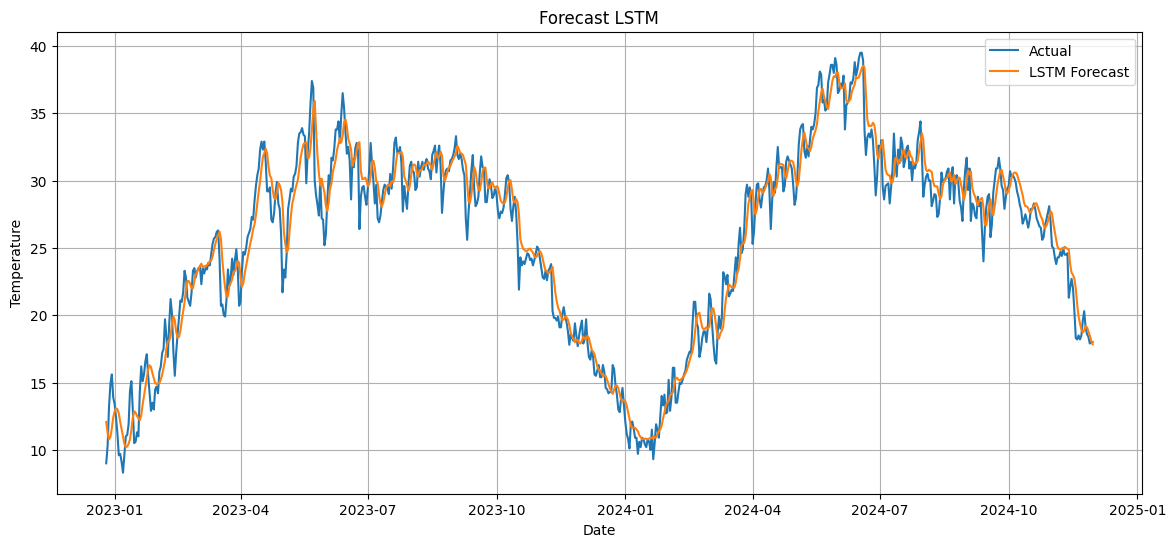

In [49]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14,6))
plt.plot(lstm_dates, y_test_real, label='Actual')
plt.plot(lstm_dates, lstm_pred, label='LSTM Forecast')
plt.title('Forecast LSTM')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.legend()
plt.grid(True)
plt.show()

Порівняння моделей

In [53]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
results = pd.DataFrame({
    'Model': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [arima_mae, prophet_mae, lstm_mae],
    'RMSE': [arima_rmse, prophet_rmse, lstm_rmse],
    'MAPE': [arima_mape, prophet_mape, lstm_mape]
})

print(results.sort_values('RMSE'))

     Model        MAE       RMSE       MAPE
2     LSTM   1.248661   1.629001   5.500973
1  Prophet   2.004680   2.590197   9.027935
0    ARIMA  10.927809  12.500912  39.591987


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


**Висновок**

У ході лабораторної роботи було виконано аналіз та побудовано моделі прогнозування щоденної температури: ARIMA, Prophet та LSTM.

Порівняння метрик точності:

* LSTM: MAE = 1.25 °C, RMSE = 1.63 °C, MAPE = 5.50%
* Prophet: MAE = 2.00 °C, RMSE = 2.59 °C, MAPE = 9.03%
* ARIMA: MAE = 10.93 °C, RMSE = 12.50 °C, MAPE = 39.59%

Найкращу якість прогнозування продемонструвала рекурентна нейронна мережа LSTM, яка точніше за інші моделі вловила нелінійні залежності та короткострокові коливання ряду. Модель Prophet показала хороші результати з урахуванням сезонності, а ARIMA виявилася найменш придатною для довгострокового прогнозування даного ряду.